Anomaly Detection

Now we'll detect unusual business behavior, such as:

unusually high/low monthly revenue
abnormal order volumes
unusual customer spending
potentially unusual transactions

For the first version, we'll use Isolation Forest on monthly business metrics. This is a good fit for your project because it gives us an actual ML-based anomaly detection component.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest

print("Libraries loaded successfully")

Libraries loaded successfully


Load orders

In [2]:
PROCESSED_PATH = "../data/processed/"

orders = pd.read_csv(
    f"{PROCESSED_PATH}orders_analytics.csv"
)

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    errors="coerce"
)

print(orders.shape)

(99441, 22)


Keep delivered orders

In [3]:
delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

print("Delivered orders:", len(delivered_orders))

Delivered orders: 96478


Create monthly business metrics

In [4]:
monthly_metrics = (
    delivered_orders
    .set_index("order_purchase_timestamp")
    .resample("MS")
    .agg(
        revenue=("total_order_value", "sum"),
        orders=("order_id", "nunique"),
        average_order_value=("total_order_value", "mean"),
        average_delivery_days=("delivery_days", "mean"),
        late_orders=("is_late", "sum")
    )
    .reset_index()
)

monthly_metrics

,order_purchase_timestamp,revenue,orders,average_order_value,average_delivery_days,late_orders
0,2016-09-01,143.46,1,143.460000,54.813194,1
1,2016-10-01,46490.66,265,175.436453,19.600559,3
2,2016-11-01,0.00,0,NaN,NaN,0
3,2016-12-01,19.62,1,19.620000,4.693021,0
4,2017-01-01,127482.37,750,169.976493,12.647044,23
5,2017-02-01,271239.32,1653,164.089123,13.168825,53
6,2017-03-01,414330.95,2546,162.738001,12.951184,142
7,2017-04-01,390812.40,2303,169.697091,14.917913,181
8,2017-05-01,566851.40,3546,159.856571,11.322363,128
9,2017-06-01,490050.37,3135,156.315907,12.011573,121


Check the data

In [5]:
print(monthly_metrics.isnull().sum())

print("\nShape:")
print(monthly_metrics.shape)

order_purchase_timestamp    0
revenue                     0
orders                      0
average_order_value         1
average_delivery_days       1
late_orders                 0
dtype: int64

Shape:
(24, 6)


In [6]:
monthly_metrics = monthly_metrics.dropna()

print("After removing missing values:", monthly_metrics.shape)

After removing missing values: (23, 6)


Select features

In [7]:
features = [
    "revenue",
    "orders",
    "average_order_value",
    "average_delivery_days",
    "late_orders"
]

X = monthly_metrics[features]

print(X.head())

     revenue  orders  average_order_value  average_delivery_days  late_orders
0     143.46       1           143.460000              54.813194            1
1   46490.66     265           175.436453              19.600559            3
3      19.62       1            19.620000               4.693021            0
4  127482.37     750           169.976493              12.647044           23
5  271239.32    1653           164.089123              13.168825           53


Train Isolation Forest

In [8]:
iso_forest = IsolationForest(
    contamination=0.10,
    random_state=42
)

monthly_metrics["anomaly_prediction"] = iso_forest.fit_predict(X)

C:\Users\Gyand\AppData\Local\Temp\ipykernel_26816\3325716283.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  monthly_metrics["anomaly_prediction"] = iso_forest.fit_predict(X)


1  → Normal
-1  → Anomaly

In [9]:
monthly_metrics["anomaly"] = (
    monthly_metrics["anomaly_prediction"]
    .map({
        1: "Normal",
        -1: "Anomaly"
    })
)

monthly_metrics[
    [
        "order_purchase_timestamp",
        "revenue",
        "orders",
        "average_order_value",
        "average_delivery_days",
        "late_orders",
        "anomaly"
    ]
]

C:\Users\Gyand\AppData\Local\Temp\ipykernel_26816\855326116.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  monthly_metrics["anomaly"] = (


,order_purchase_timestamp,revenue,orders,average_order_value,average_delivery_days,late_orders,anomaly
0,2016-09-01,143.46,1,143.460000,54.813194,1,Anomaly
1,2016-10-01,46490.66,265,175.436453,19.600559,3,Normal
3,2016-12-01,19.62,1,19.620000,4.693021,0,Anomaly
4,2017-01-01,127482.37,750,169.976493,12.647044,23,Normal
5,2017-02-01,271239.32,1653,164.089123,13.168825,53,Normal
6,2017-03-01,414330.95,2546,162.738001,12.951184,142,Normal
7,2017-04-01,390812.40,2303,169.697091,14.917913,181,Normal
8,2017-05-01,566851.40,3546,159.856571,11.322363,128,Normal
9,2017-06-01,490050.37,3135,156.315907,12.011573,121,Normal
10,2017-07-01,566299.08,3872,146.254928,11.592732,133,Normal


Show detected anomalies

In [10]:
anomalies = monthly_metrics[
    monthly_metrics["anomaly"] == "Anomaly"
].copy()

print("Number of anomalous months:", len(anomalies))

anomalies[
    [
        "order_purchase_timestamp",
        "revenue",
        "orders",
        "average_order_value",
        "average_delivery_days",
        "late_orders"
    ]
]

Number of anomalous months: 3


,order_purchase_timestamp,revenue,orders,average_order_value,average_delivery_days,late_orders
0,2016-09-01,143.46,1,143.460000,54.813194,1
3,2016-12-01,19.62,1,19.620000,4.693021,0
18,2018-03-01,1120598.24,7003,160.016884,16.301410,1496


Visualize revenue anomalies

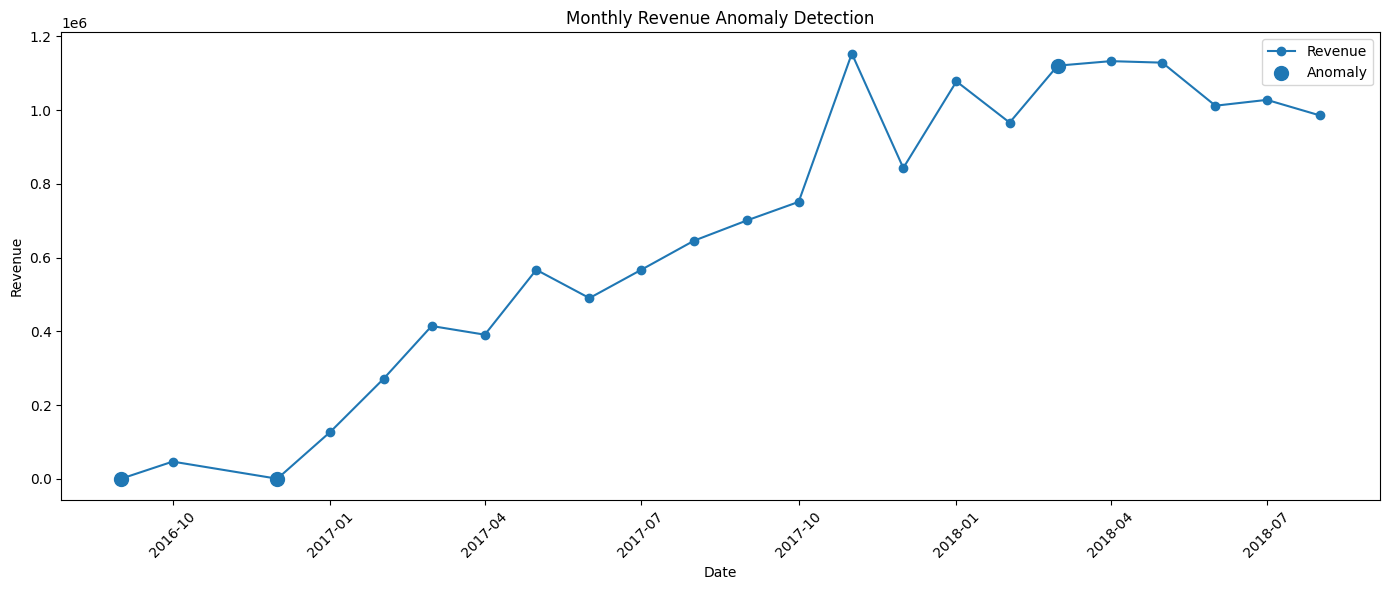

In [11]:
plt.figure(figsize=(14, 6))

normal_data = monthly_metrics[
    monthly_metrics["anomaly"] == "Normal"
]

anomaly_data = monthly_metrics[
    monthly_metrics["anomaly"] == "Anomaly"
]

plt.plot(
    monthly_metrics["order_purchase_timestamp"],
    monthly_metrics["revenue"],
    marker="o",
    label="Revenue"
)

plt.scatter(
    anomaly_data["order_purchase_timestamp"],
    anomaly_data["revenue"],
    s=100,
    label="Anomaly"
)

plt.title("Monthly Revenue Anomaly Detection")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Save anomaly results

In [12]:
monthly_metrics.to_csv(
    f"{PROCESSED_PATH}monthly_anomaly_detection.csv",
    index=False
)

anomalies.to_csv(
    f"{PROCESSED_PATH}revenue_anomalies.csv",
    index=False
)

print("Anomaly detection results saved successfully.")

Anomaly detection results saved successfully.


data/processed/

├── monthly_anomaly_detection.csv

└
── revenue_anomalies.csv

User
 │

 │
  "Did anything unusual happen in sales?"
 ↓

Anomaly Agent
 │

 ↓

Isolation Forest Tool
 │

 ↓

monthly_anomaly_detection.csv
 │

 ↓

Detected anomalies
 │

 ↓

Insight Agent
 │

 ↓
 
"Revenue/order behavior was unusual in..."